# Week 2 — Advanced Data Visualization and Storytelling

## Introduction

In this week, I will use Python to create visualizations that explain patterns and insights in the Bank Marketing dataset.
The goal is to present the findings clearly so that even a non-technical person can understand them.

In [2]:
# import required libraries

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Loading the Dataset

I will use the Bank Marketing dataset from Week 1 to create visualizations and identify meaningful patterns.

In [3]:
df = pd.read_csv("../../data/bank-full.csv")

#display five rows
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# 1.Customer Subscription Distribution

This visualization compares the number of customers who subscribed to a term deposit with those who did not.

A bar chart makes the difference between the two categories easy to understand.

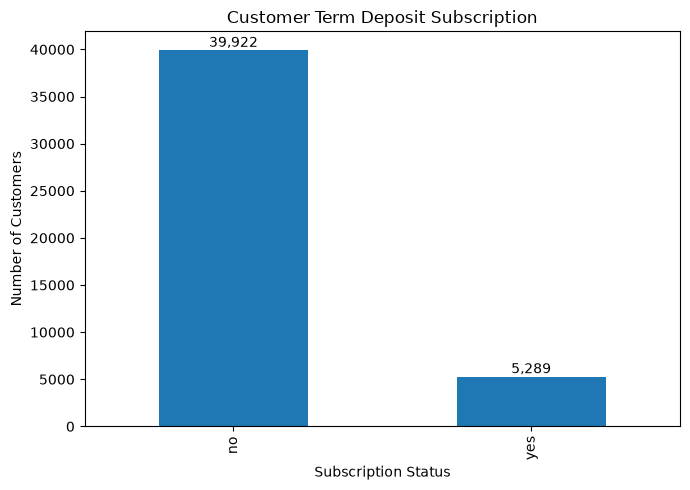

In [4]:
# Count customers in each subscription category
subscription_counts = df["y"].value_counts()

# Create the bar chart
ax = subscription_counts.plot(kind="bar", figsize=(7, 5))

# Add the chart title and axis labels
plt.title("Customer Term Deposit Subscription")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")

# Display the customer count above each bar
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

# Display the chart
plt.tight_layout()
plt.show()

### Interpretation

The dataset contains 45,211 customers. Of these, 39,922 did not subscribe to a term deposit, while 5,289 subscribed.

The chart highlights the imbalance between the two subscription categories. Comparing subscription rates across customer groups can provide additional insights beyond the overall customer counts.

## 2. Subscription Rate by Job Category

This visualization compares term deposit subscription rates across job categories.

I will use percentages instead of customer counts because the number of customers varies across occupations.

job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: subscribed, dtype: float64


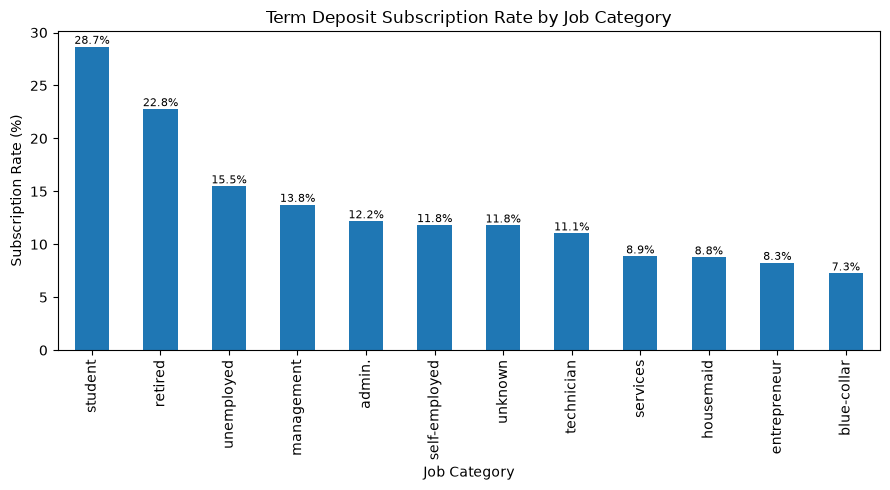

In [5]:
# Calculate the subscription rate for each job category
job_subscription_rate = (
    df.assign(subscribed=df["y"].eq("yes"))
      .groupby("job")["subscribed"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

# Create the bar chart
ax = job_subscription_rate.plot(kind="bar", figsize=(9, 5))

# Add the chart title and axis labels
plt.title("Term Deposit Subscription Rate by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Subscription Rate (%)")

# Display percentage labels above the bars
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=8
    )

# Display subscription rates by job category
print(job_subscription_rate.round(2))

# Display the chart
plt.tight_layout()
plt.show()

### Interpretation

The chart compares subscription rates across job categories. The percentage labels make it easier to identify occupations with relatively higher and lower subscription rates.

Comparing percentages provides a fairer comparison when customer group sizes differ. These findings can help the bank understand subscription patterns across professional groups.


## 3. Subscription Rate by Age Group

This visualization compares term deposit subscription rates across different age groups.

A percentage-based bar chart helps compare groups of different sizes.

age_group
18–25    23.95
26–35    12.00
36–45     9.39
46–55     9.35
56–65    14.12
66+      42.61
Name: subscribed, dtype: float64


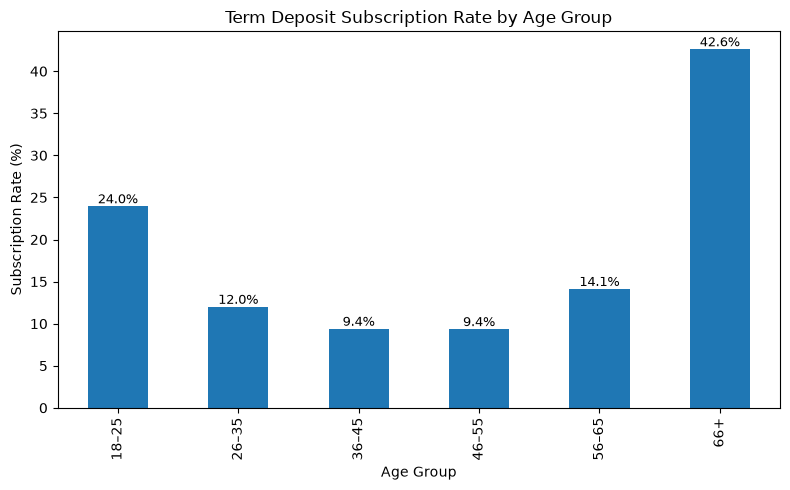

In [6]:
# Divide customers into age groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=["18–25", "26–35", "36–45", "46–55", "56–65", "66+"]
)

# Calculate subscription rates for each age group
age_subscription_rate = (
    df.assign(subscribed=df["y"].eq("yes"))
      .groupby("age_group", observed=False)["subscribed"]
      .mean()
      .mul(100)
)

# Create the bar chart
ax = age_subscription_rate.plot(kind="bar", figsize=(8, 5))

# Add the chart title and axis labels
plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")

# Display percentage labels above the bars
for bar in ax.patches:
    if pd.notna(bar.get_height()):
        ax.annotate(
            f"{bar.get_height():.1f}%",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
            fontsize=9
        )
# Display subscription rates by age group
print(age_subscription_rate.round(2))

# Display the chart
plt.tight_layout()
plt.show()

### Interpretation

The chart compares subscription rates across age groups. The percentage labels help identify groups with relatively higher and lower subscription rates.

This analysis helps explore the relationship between customer age and term deposit subscription. The results describe patterns in this dataset and do not establish that age causes a customer to subscribe.

## 4. Subscription Rate by Education Level

This visualization compares term deposit subscription rates across education levels.

A percentage-based bar chart makes it easier to compare the subscription patterns of different education groups.

education
tertiary     15.01
unknown      13.57
secondary    10.56
primary       8.63
Name: subscribed, dtype: float64


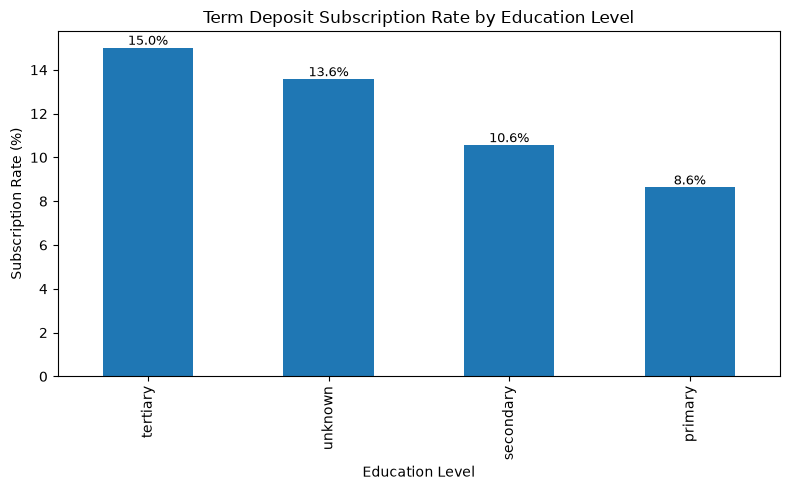

In [7]:
# Calculate subscription rates for each education level
education_subscription_rate = (
    df.assign(subscribed=df["y"].eq("yes"))
      .groupby("education")["subscribed"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

# Create the bar chart
ax = education_subscription_rate.plot(kind="bar", figsize=(8, 5))

# Add the chart title and axis labels
plt.title("Term Deposit Subscription Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")

# Display percentage labels above the bars
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=9
    )
# Display subscription rates by education level
print(education_subscription_rate.round(2))

# Display the chart
plt.tight_layout()
plt.show()

### Interpretation

The chart compares subscription rates across education levels. The percentage labels help identify groups with relatively higher and lower subscription rates.

This comparison can help the bank explore how education level relates to customer subscription patterns.

## 5. Subscription Rate by Marital Status

This visualization compares term deposit subscription rates among single, married, and divorced customers.

Percentages are used to make the comparison fairer when group sizes differ.

marital
single      14.95
divorced    11.95
married     10.12
Name: subscribed, dtype: float64


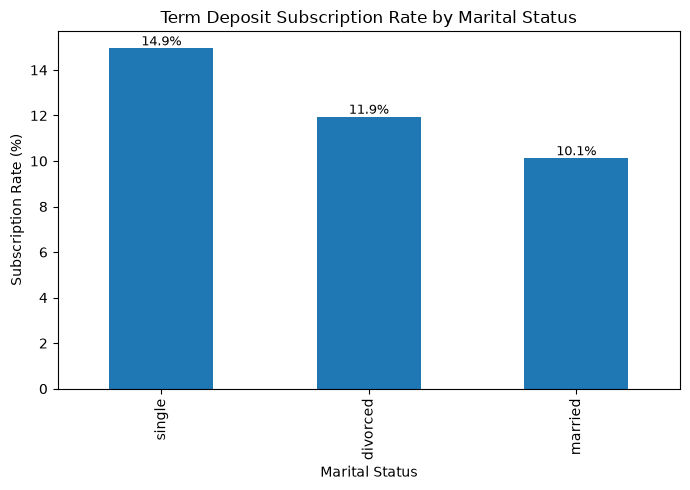

In [8]:
# Calculate subscription rates for each marital status
marital_subscription_rate = (
    df.assign(subscribed=df["y"].eq("yes"))
      .groupby("marital")["subscribed"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

# Create the bar chart
ax = marital_subscription_rate.plot(kind="bar", figsize=(7, 5))

# Add the chart title and axis labels
plt.title("Term Deposit Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")

# Display percentage labels above the bars
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=9
    )
# Display subscription rates by marital status
print(marital_subscription_rate.round(2))
# Display the chart
plt.tight_layout()
plt.show()

### Interpretation

The chart compares subscription rates across marital status groups. The percentage labels make the differences between the groups easier to understand.

This comparison helps explore how marital status relates to term deposit subscription patterns. The results show associations in the dataset rather than cause-and-effect relationships.

## 6. Subscription Rate by Contact Type

This visualization compares term deposit subscription rates across different contact methods.

A percentage-based bar chart helps compare the subscription rates of customers contacted through cellular phones and telephone.

contact
cellular     14.92
telephone    13.42
unknown       4.07
Name: subscribed, dtype: float64


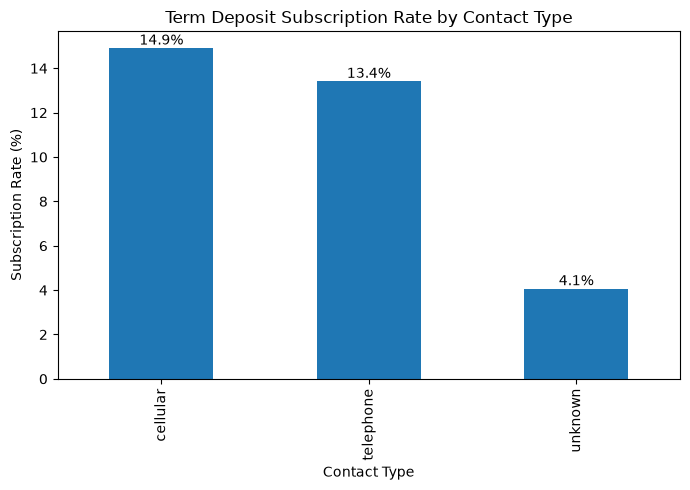

In [9]:
# Calculate subscription rates for each contact type
contact_subscription_rate = (
    df.assign(subscribed=df["y"].eq("yes"))
      .groupby("contact")["subscribed"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

ax = contact_subscription_rate.plot(kind="bar", figsize=(7, 5))

# Add the chart title and axis labels
plt.title("Term Deposit Subscription Rate by Contact Type")
plt.xlabel("Contact Type")
plt.ylabel("Subscription Rate (%)")

# Display percentage labels above the bars
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )
# Display subscription rates by contact type
print(contact_subscription_rate.round(2))

# Display the chart
plt.tight_layout()
plt.show()

### Interpretation

The chart compares term deposit subscription rates across contact methods. The percentage labels help identify which contact method has a relatively higher subscription rate.

This comparison may help the bank evaluate customer responses to different contact methods. However, the results show an association and do not prove that the contact method caused a customer to subscribe.

In [11]:
# Display the subscription rates by contact type

print(contact_subscription_rate.round(2))

# Display the number of customers in each contact category

print("\nCustomer count by contact type:")
print(df["contact"].value_counts())

contact
cellular     14.92
telephone    13.42
unknown       4.07
Name: subscribed, dtype: float64

Customer count by contact type:
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64


## Customer Balance Distribution by Subscription Status

This box plot compares the account balances of customers who subscribed to a term deposit with those who did not.

A box plot helps identify differences in the distributions, typical balance ranges, and potential outliers.

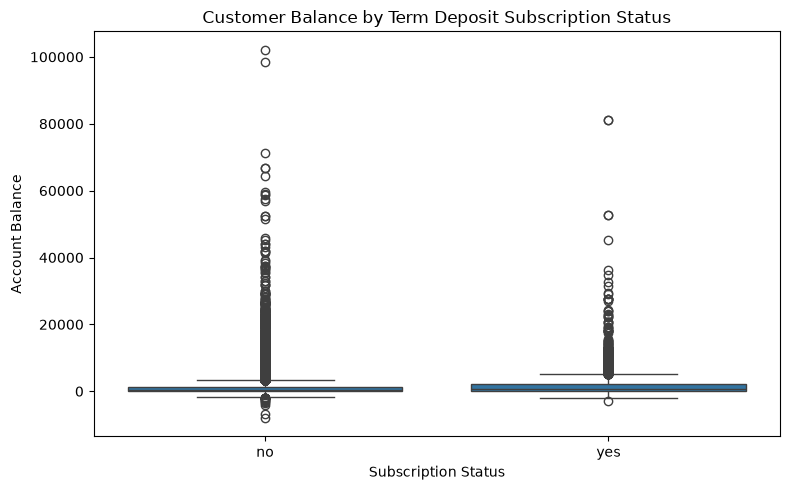

In [12]:
# Create a box plot to compare account balances
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="y", y="balance")

# Add the chart title and axis labels
plt.title("Customer Balance by Term Deposit Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Account Balance")

# Display the chart
plt.tight_layout()
plt.show()

## Subscription Rate by Month

This visualization compares term deposit subscription rates across the months in which customers were contacted.

A line chart helps show how the subscription rate changes from one month to another. The months will be arranged in calendar order rather than alphabetical order.

month
jan    10.12
feb    16.65
mar    51.99
apr    19.68
may     6.72
jun    10.22
jul     9.09
aug    11.01
sep    46.46
oct    43.77
nov    10.15
dec    46.73
Name: subscribed, dtype: float64


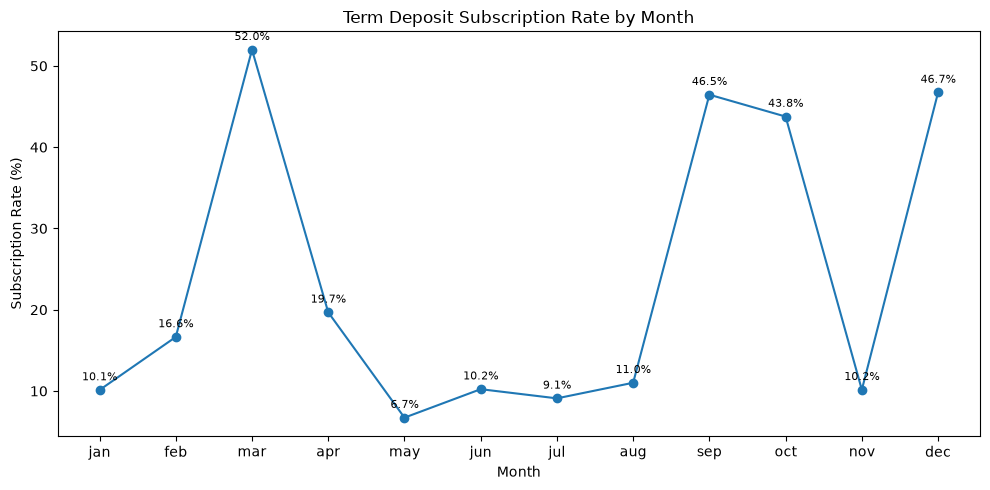

In [14]:
# Arrange months in calendar order
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

# Calculate the subscription rate for each month
monthly_subscription_rate = (
    df.assign(subscribed=df["y"].eq("yes"))
      .groupby("month")["subscribed"]
      .mean()
      .mul(100)
      .reindex(month_order)
)

# Create the line chart
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_subscription_rate.index,
    monthly_subscription_rate.values,
    marker="o"
)

# Add the chart title and axis labels
plt.title("Term Deposit Subscription Rate by Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")

# Add percentage labels to the points
for month, rate in monthly_subscription_rate.items():
    if pd.notna(rate):
        plt.annotate(
            f"{rate:.1f}%",
            (month, rate),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=8
        )
# Display the subscription rate for each month
print(monthly_subscription_rate.round(2))

# Display the chart
plt.tight_layout()
plt.show()

### Interpretation

The line chart shows how term deposit subscription rates vary across the months. The percentage labels make it easier to identify months with relatively higher and lower rates.

These differences may help the bank investigate whether campaign timing is associated with customer responses. However, monthly differences alone do not establish that the month caused customers to subscribe.

In [15]:
# Display the subscription rates by job category
print("Subscription Rate by Job:")
print(job_subscription_rate.round(2))

# Display the subscription rates by age group
print("\nSubscription Rate by Age Group:")
print(age_subscription_rate.round(2))

# Display the subscription rates by education
print("\nSubscription Rate by Education:")
print(education_subscription_rate.round(2))

# Display the subscription rates by marital status
print("\nSubscription Rate by Marital Status:")
print(marital_subscription_rate.round(2))

# Display the subscription rates by contact type
print("\nSubscription Rate by Contact Type:")
print(contact_subscription_rate.round(2))

# Display the subscription rates by month
print("\nSubscription Rate by Month:")
print(monthly_subscription_rate.round(2))

Subscription Rate by Job:
job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: subscribed, dtype: float64

Subscription Rate by Age Group:
age_group
18–25    23.95
26–35    12.00
36–45     9.39
46–55     9.35
56–65    14.12
66+      42.61
Name: subscribed, dtype: float64

Subscription Rate by Education:
education
tertiary     15.01
unknown      13.57
secondary    10.56
primary       8.63
Name: subscribed, dtype: float64

Subscription Rate by Marital Status:
marital
single      14.95
divorced    11.95
married     10.12
Name: subscribed, dtype: float64

Subscription Rate by Contact Type:
contact
cellular     14.92
telephone    13.42
unknown       4.07
Name: subscribed, dtype: float64

Subscription Rate by Month:
month
jan    10.12
feb    16.65
mar    51.99
ap

## Methods

The Bank Marketing dataset was used to explore customer subscription patterns.

Python libraries, including Pandas, Matplotlib, and Seaborn, were used to analyze the data and create visualizations.

Bar charts were used to compare subscription rates across customer groups. A box plot was used to examine account balance distributions, while a line chart was used to compare subscription rates across months.

Subscription rates were calculated as the percentage of customers who subscribed within each group. This approach allows comparisons between groups of different sizes.

The visualizations were used to identify patterns and differences in the dataset. These findings describe associations and should not be interpreted as proof of cause and effect.

## Conclusion

The visualizations helped explore customer subscription patterns in the Bank Marketing dataset.

The analysis compared subscription rates across job categories, age groups, education levels, marital status, contact types, and months. The box plot also helped examine account balance distributions for customers who subscribed and those who did not.

Using percentages made comparisons between groups of different sizes easier. The box plot and line chart provided additional perspectives beyond simple category comparisons.

These findings can help the bank identify customer groups and campaign periods for further investigation. However, the observed patterns do not establish cause-and-effect relationships.

Overall, this analysis demonstrates how different visualization techniques can communicate patterns and support data-driven decision-making.

In [16]:
# Collect key numerical findings for the report

print("Total customers:", len(df))

print("\nSubscription counts:")
print(df["y"].value_counts())

print("\nSubscription rates by job:")
print(job_subscription_rate.round(2))

print("\nSubscription rates by age group:")
print(age_subscription_rate.round(2))

print("\nSubscription rates by education:")
print(education_subscription_rate.round(2))

print("\nSubscription rates by marital status:")
print(marital_subscription_rate.round(2))

print("\nSubscription rates by contact type:")
print(contact_subscription_rate.round(2))

print("\nSubscription rates by month:")
print(monthly_subscription_rate.round(2))

Total customers: 45211

Subscription counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription rates by job:
job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: subscribed, dtype: float64

Subscription rates by age group:
age_group
18–25    23.95
26–35    12.00
36–45     9.39
46–55     9.35
56–65    14.12
66+      42.61
Name: subscribed, dtype: float64

Subscription rates by education:
education
tertiary     15.01
unknown      13.57
secondary    10.56
primary       8.63
Name: subscribed, dtype: float64

Subscription rates by marital status:
marital
single      14.95
divorced    11.95
married     10.12
Name: subscribed, dtype: float64

Subscription rates by contact type:
contact
cellular     14.92
telephone    13.42
unknown       4.07
Name